# Evaluasi Verifikasi Realisasi Indikator RPJMN 2025-2029
Gemma 4 26B A4B vs Qwen3 30B A3B

## 1. Setup

In [33]:
import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

DATA_OUT = Path("../data/output")

# Nama pendek untuk tabel dan grafik
MODELS = {
    "gemma-4-26b-a4b-it":               "Gemma 4 26B A4B",
    "watsonx-qwen3-30b-a3b-instruct-2": "Qwen3 30B A3B",
}
ORDER = list(MODELS.values())
G, Q = ORDER

# Warna mengikuti model, tidak pernah dipakai untuk arti lain
COLORS = {G: "#2a78d6", Q: "#eb6834"}
# Skor judge 0-1-2 berurutan, jadi satu warna dari terang ke gelap
WARNA_SKOR = {0: "#86b6ef", 1: "#3987e5", 2: "#184f95"}
CMAP_BIRU = LinearSegmentedColormap.from_list("biru", ["#ffffff", "#cde2fb", "#2a78d6"])
ABU = "#c3c2b7"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": ABU, "axes.labelcolor": "#52514e", "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return (c - h, c + h)


def fmt_ci(k, n):
    # proporsi beserta pembilang/penyebut dan interval Wilson 95%
    lo, hi = wilson(k, n)
    return f"{k/n:.1%} ({k}/{n}) [{lo:.1%}-{hi:.1%}]" if n else "-"

## 2. Muat dan validasi

In [34]:
def latest(pattern):
    files = sorted(DATA_OUT.glob(pattern))
    if not files:
        raise FileNotFoundError(pattern)
    return files[-1]


frames, raws = [], []
for slug, nama in MODELS.items():
    f_det = latest(f"detail_{slug}_serper_*.csv")
    f_raw = DATA_OUT / f"raw_{slug}_serper.jsonl"
    d = pd.read_csv(f_det, encoding="utf-8-sig")
    d["model_nama"] = nama
    frames.append(d)

    with open(f_raw, encoding="utf-8") as fh:
        for line in fh:
            r = json.loads(line)
            raws.append({"model_nama": nama, "row_no": r["row_no"],
                         "tool_calls_log": r.get("tool_calls_log") or []})
    print(f"{nama:<16}: {f_det.name}  ({len(d)} baris)")

df = pd.concat(frames, ignore_index=True)
raw = pd.DataFrame(raws)

raw["n_hasil"] = raw["tool_calls_log"].apply(lambda L: sum(len(t.get("hasil") or []) for t in L))
df = df.merge(raw[["model_nama", "row_no", "n_hasil"]], on=["model_nama", "row_no"], how="left")
log_map = {(r["model_nama"], r["row_no"]): r["tool_calls_log"] for _, r in raw.iterrows()}

for c in ["gold", "pred", "benar", "domain_goid", "url_dari_search", "gold_suspect"]:
    df[c] = df[c].astype(bool)

wide = df.pivot(index="row_no", columns="model_nama", values=["pred", "benar"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide = wide.join(df.drop_duplicates("row_no").set_index("row_no")[["gold", "sektor", "kl", "sub_indikator"]])

cek = df.groupby("row_no")["gold"].nunique()
assert (cek == 1).all(), "Gold berbeda antar file model"
assert df.groupby("model_nama")["row_no"].nunique().eq(292).all(), "Jumlah baris tidak 292"
assert (df["benar"] == (df["gold"] == df["pred"])).all(), "Kolom benar tidak konsisten dengan gold dan pred"

n_true, n_false = int(wide["gold"].sum()), int((~wide["gold"]).sum())
print(f"\nStatus run : {df.groupby('model_nama')['status'].value_counts().to_dict()}")
print(f"Gold       : {n_true} TRUE, {n_false} FALSE dari {len(wide)} indikator")
print(f"Baseline 'selalu TRUE' sudah mencapai akurasi {n_true/len(wide):.1%}")

Gemma 4 26B A4B : detail_gemma-4-26b-a4b-it_serper_20260918_113127.csv  (292 baris)
Qwen3 30B A3B   : detail_watsonx-qwen3-30b-a3b-instruct-2_serper_20260917_150324.csv  (292 baris)

Status run : {('Gemma 4 26B A4B', 'OK'): 292, ('Qwen3 30B A3B', 'OK'): 292}
Gold       : 286 TRUE, 6 FALSE dari 292 indikator
Baseline 'selalu TRUE' sudah mencapai akurasi 97.9%


## 3. Metrik per kelas

In [35]:
def metrik(gold, pred):
    gold, pred = np.asarray(gold, bool), np.asarray(pred, bool)
    tp = int(( gold &  pred).sum()); fn = int(( gold & ~pred).sum())
    fp = int((~gold &  pred).sum()); tn = int((~gold & ~pred).sum())
    div = lambda a, b: a / b if b else np.nan
    rec_t, rec_f = div(tp, tp + fn), div(tn, tn + fp)
    pre_t, pre_f = div(tp, tp + fp), div(tn, tn + fn)
    f1 = lambda p, r: 0.0 if (pd.isna(p) or pd.isna(r) or p + r == 0) else 2 * p * r / (p + r)
    return {
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
        "Precision TRUE": pre_t, "Recall TRUE": rec_t, "F1 TRUE": f1(pre_t, rec_t),
        "Precision FALSE": pre_f, "Recall FALSE": rec_f, "F1 FALSE": f1(pre_f, rec_f),
        "Balanced accuracy": (rec_t + rec_f) / 2,
        "Macro F1": (f1(pre_t, rec_t) + f1(pre_f, rec_f)) / 2,
    }


hasil = {nama: metrik(d["gold"], d["pred"]) for nama, d in df.groupby("model_nama")}
hasil["Baseline: selalu TRUE"] = metrik(wide["gold"], np.ones(len(wide), bool))
tabel_metrik = pd.DataFrame(hasil)[ORDER + ["Baseline: selalu TRUE"]]

HITUNGAN = ["TP", "FN", "FP", "TN"]
tampil = pd.DataFrame({
    kol: [f"{int(v)}" if idx in HITUNGAN else ("-" if pd.isna(v) else f"{v:.1%}")
          for idx, v in tabel_metrik[kol].items()]
    for kol in tabel_metrik.columns
}, index=tabel_metrik.index)
tampil

,Gemma 4 26B A4B,Qwen3 30B A3B,Baseline: selalu TRUE
TP,270,172,286
FN,16,114,0
FP,5,5,6
TN,1,1,0
Precision TRUE,98.2%,97.2%,97.9%
Recall TRUE,94.4%,60.1%,100.0%
F1 TRUE,96.3%,74.3%,99.0%
Precision FALSE,5.9%,0.9%,-
Recall FALSE,16.7%,16.7%,0.0%
F1 FALSE,8.7%,1.7%,0.0%


In [36]:
# Interval Wilson 95% untuk keempat proporsi per kelas
rows = []
for nama in ORDER:
    m = hasil[nama]
    rows.append({
        "Model": nama,
        "Recall TRUE": fmt_ci(m["TP"], m["TP"] + m["FN"]),
        "Precision TRUE": fmt_ci(m["TP"], m["TP"] + m["FP"]),
        "Recall FALSE": fmt_ci(m["TN"], m["TN"] + m["FP"]),
        "Precision FALSE": fmt_ci(m["TN"], m["TN"] + m["FN"]),
    })
tabel_ci = pd.DataFrame(rows).set_index("Model").T
tabel_ci

Model,Gemma 4 26B A4B,Qwen3 30B A3B
Recall TRUE,94.4% (270/286) [91.1%-96.5%],60.1% (172/286) [54.4%-65.6%]
Precision TRUE,98.2% (270/275) [95.8%-99.2%],97.2% (172/177) [93.6%-98.8%]
Recall FALSE,16.7% (1/6) [3.0%-56.4%],16.7% (1/6) [3.0%-56.4%]
Precision FALSE,5.9% (1/17) [1.0%-27.0%],0.9% (1/115) [0.2%-4.8%]


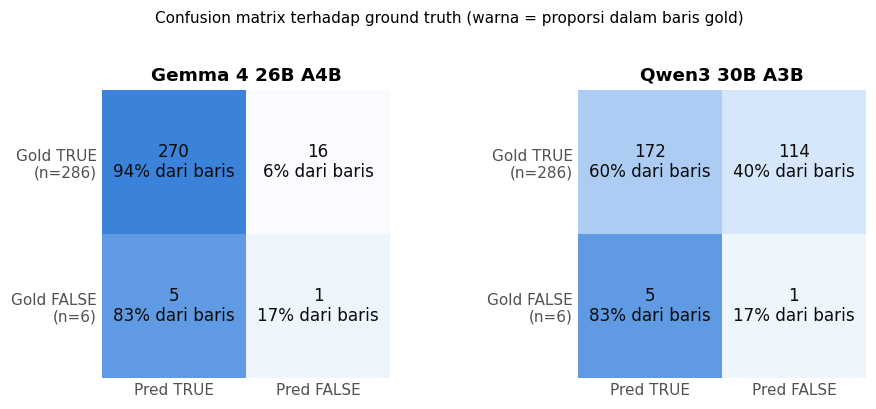

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, nama in zip(axes, ORDER):
    m = hasil[nama]
    cm = np.array([[m["TP"], m["FN"]], [m["FP"], m["TN"]]])
    # warna dihitung per baris, supaya baris gold FALSE (6 indikator) tetap terbaca
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=CMAP_BIRU, vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v}\n{v/cm[i].sum():.0%} dari baris", ha="center", va="center",
                color="#0b0b0b", fontsize=11)
    ax.set_xticks([0, 1], ["Pred TRUE", "Pred FALSE"])
    ax.set_yticks([0, 1], [f"Gold TRUE\n(n={n_true})", f"Gold FALSE\n(n={n_false})"])
    ax.set_title(nama)
    ax.grid(False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Confusion matrix terhadap ground truth (warna = proporsi dalam baris gold)", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

### 3.1 Sensitivitas tanpa baris `gold_suspect` (no=11)

In [38]:
print("Baris gold_suspect:", sorted(int(x) for x in df.loc[df["gold_suspect"], "row_no"].unique()))

tanpa11 = df[~df["gold_suspect"]]
sens = pd.DataFrame({nama: metrik(d["gold"], d["pred"]) for nama, d in tanpa11.groupby("model_nama")})[ORDER]

KOL_SENS = ["Recall TRUE", "Recall FALSE", "Balanced accuracy", "Macro F1"]
banding = pd.concat({"Gold asli": tabel_metrik.loc[KOL_SENS, ORDER],
                     "Tanpa no=11": sens.loc[KOL_SENS]}, axis=1).swaplevel(axis=1)[ORDER]
display(banding.style.format("{:.1%}"))
for nama in ORDER:
    print(f"{nama:<16}: recall FALSE {hasil[nama]['TN']}/{hasil[nama]['TN'] + hasil[nama]['FP']}"
          f" -> {int(sens.loc['TN', nama])}/{int(sens.loc['TN', nama] + sens.loc['FP', nama])}")

Baris gold_suspect: [11]


Gemma 4 26B A4B : recall FALSE 1/6 -> 1/5
Qwen3 30B A3B   : recall FALSE 1/6 -> 1/5


## 4. Evaluasi summary: groundedness dan relevansi (LLM-as-judge)

### 4.1 Input dan prompt

In [39]:
JUDGE_MODEL = "llama3.1:8b"                      # tag Ollama untuk Llama 3.1 8B (Meta)
JUDGE_URL   = "http://localhost:11434/v1"        # server Ollama lokal, antarmuka kompatibel OpenAI
F_JUDGE     = DATA_OUT / "judge_groundedness_relevansi.csv"


def sumber_teks(tool_calls_log, url, maks_lain=6):
    # pisahkan cuplikan sumber yang dikutip model dari cuplikan hasil pencarian lain
    dikutip, lain, lihat = [], [], set()
    for t in tool_calls_log:
        for h in (t.get("hasil") or []):
            u = h.get("url")
            if not u or u in lihat:
                continue
            lihat.add(u)
            s = f"- {h.get('judul') or ''}: {h.get('cuplikan') or ''}"
            (dikutip if (url and u == url) else lain).append(s)
    return "\n".join(dikutip), "\n".join(lain[:maks_lain])


def muat_baris():
    rows = []
    for _, r in df.iterrows():
        url = r["source_url_pred"] if pd.notna(r["source_url_pred"]) else None
        dik, lain = sumber_teks(log_map[(r["model_nama"], r["row_no"])], url)
        rows.append({"model_nama": r["model_nama"], "row_no": int(r["row_no"]),
                     "indikator": r["sub_indikator"],
                     "target": f"{r['target_2025']} {r['satuan']}",
                     "ringkasan": r["summary_pred"],
                     "sumber_dikutip": dik, "hasil_lain": lain})
    return rows


SYS_GROUND = '''Kamu penilai GROUNDEDNESS. Periksa apakah isi RINGKASAN didukung oleh teks sumber yang diberikan.
Jangan memakai pengetahuan di luar teks sumber. Perhatikan angka, nama kegiatan, lokasi, dan tahun.
Skor:
2 = semua klaim penting didukung SUMBER_DIKUTIP atau HASIL_LAIN
1 = sebagian klaim didukung, sebagian tidak ditemukan di teks
0 = klaim utama tidak ditemukan di teks sumber (diduga dikarang atau dari pengetahuan model sendiri)
Catatan: bila RINGKASAN menyatakan bukti tidak ditemukan, beri 2 jika teks sumber memang tidak memuat bukti itu.
Balas HANYA JSON: {"skor": 0, "alasan": "maks 1 kalimat"}'''

SYS_REL = '''Kamu penilai RELEVANSI. Nilai apakah teks membahas INDIKATOR yang ditanyakan.
Skor:
2 = membahas indikator yang sama (topik, objek, dan wilayah/sektor cocok)
1 = terkait tetapi bukan indikator yang persis sama (program induk, wilayah atau kelompok sasaran berbeda)
0 = tidak terkait
Nilai dua hal: "ringkasan" (isi RINGKASAN) dan "sumber" (isi SUMBER_DIKUTIP).
Balas HANYA JSON: {"ringkasan": 0, "sumber": 0, "alasan": "maks 1 kalimat"}'''


def prompt_ground(r):
    return (f"RINGKASAN: {r['ringkasan']}\n\n"
            f"SUMBER_DIKUTIP:\n{r['sumber_dikutip'] or '(tidak ada)'}\n\n"
            f"HASIL_LAIN:\n{r['hasil_lain'] or '(tidak ada)'}")


def prompt_rel(r):
    return (f"INDIKATOR: {r['indikator']} (target 2025: {r['target']})\n\n"
            f"RINGKASAN: {r['ringkasan']}\n\n"
            f"SUMBER_DIKUTIP:\n{r['sumber_dikutip'] or '(tidak ada)'}")


baris_judge = muat_baris()
# cuplikan sumber yang dikutip, dipakai lagi di 4.4 dan 6.4
df["teks_sumber_dikutip"] = pd.Series([r["sumber_dikutip"].replace("\n", " ") for r in baris_judge], index=df.index)
n_tanpa_sumber = sum(1 for r in baris_judge if not r["sumber_dikutip"])
terpanjang = max(len(SYS_GROUND) + len(prompt_ground(r)) for r in baris_judge)
print(f"Baris yang akan dinilai        : {len(baris_judge)} ({len(baris_judge) * 2} panggilan)")
print(f"Tanpa sumber yang dikutip      : {n_tanpa_sumber} (relevansi sumber dikosongkan)")
print(f"Prompt terpanjang              : {terpanjang} karakter")
print("\n--- Contoh prompt groundedness, baris pertama ---")
print(prompt_ground(baris_judge[0])[:900])

Baris yang akan dinilai        : 584 (1168 panggilan)
Tanpa sumber yang dikutip      : 68 (relevansi sumber dikosongkan)
Prompt terpanjang              : 2726 karakter

--- Contoh prompt groundedness, baris pertama ---
RINGKASAN: Program berjalan, ditandai dengan adanya kegiatan verifikasi lapangan oleh tim verifikator STBM 5 Pilar tingkat nasional di berbagai daerah seperti Kota Malang dan Blitar pada Oktober 2025. Kegiatan ini merupakan bagian dari proses penilaian untuk mencapai status deklarasi 5 pilar STBM di tingkat kabupaten/kota.

SUMBER_DIKUTIP:
- Verifikator STBM 5 Pilar Kunjungi Kota Malang: Adapun lima STBM mencakup Stop Buang Air Besar Sembarangan (BABS), Cuci Tangan Pakai Sabun (CTPS), Pengolahan Air Minum dan Makanan Rumah Tangga ...

HASIL_LAIN:
- Deklarasi 5 Pilar STBM dan Penggalangan Komitmen Lintas Sektor: Adapun 5 Pilar STBM yang dimaksud adalah sebagai berikut: 1. Stop Buang Air Besar Sembarangan, kondisi ketika setiap individu dalam suatu ...
- Hay Sobat Healthie

### 4.2 Menjalankan judge

In [40]:
# Prasyarat: Ollama berjalan, `ollama pull llama3.1:8b`, `pip install openai`.
# Hasil disimpan baris demi baris; run yang terputus dilanjutkan dengan menjalankan ulang sel ini.
JALANKAN_JUDGE = True     # ubah ke True untuk menjalankan judge
BATAS = None               # isi 10 untuk uji coba; None = semua baris yang belum dinilai

KOL_JUDGE = ["judge_groundedness", "judge_rel_ringkasan", "judge_rel_sumber",
             "alasan_groundedness", "alasan_relevansi"]


class JudgeTakTerhubung(Exception):
    pass


def parse_json(txt):
    t = re.sub(r"```(?:json)?", "", txt or "").strip()
    m = re.search(r"\{.*\}", t, re.S)
    try:
        return json.loads(m.group(0)) if m else None
    except Exception:
        return None


def skor_valid(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool) and v in (0, 1, 2)


def panggil(client, system, user, kunci, coba=2):
    # Kembalikan dict skor, atau None bila keluaran tetap tidak valid setelah `coba` kali.
    # Kegagalan koneksi/timeout pada percobaan terakhir dilempar sebagai JudgeTakTerhubung.
    galat = None
    for _ in range(coba):
        try:
            resp = client.chat.completions.create(
                model=JUDGE_MODEL, temperature=0, max_tokens=150, timeout=180,
                messages=[{"role": "system", "content": system},
                          {"role": "user", "content": user}])
        except Exception as e:
            galat = e
            continue
        galat = None
        j = parse_json(resp.choices[0].message.content)
        if j and all(skor_valid(j.get(k)) for k in kunci):
            return j
    if galat is not None:
        raise JudgeTakTerhubung(repr(galat))
    return None


def jalankan(batas=None):
    from openai import OpenAI
    client = OpenAI(base_url=JUDGE_URL, api_key="ollama")

    sudah = set()
    if F_JUDGE.exists():
        s = pd.read_csv(F_JUDGE, encoding="utf-8-sig")
        sudah = set(zip(s["model_nama"], s["row_no"]))
    baris = [r for r in muat_baris() if (r["model_nama"], r["row_no"]) not in sudah]
    if batas:
        baris = baris[:batas]
    print(f"Dinilai: {len(baris)} baris (dilewati karena sudah ada: {len(sudah)})")

    gagal_beruntun, n_tulis = 0, 0
    for i, r in enumerate(baris, 1):
        ada_sumber = bool(r["sumber_dikutip"])
        try:
            g = panggil(client, SYS_GROUND, prompt_ground(r), ["skor"])
            v = panggil(client, SYS_REL, prompt_rel(r), ["ringkasan"] + (["sumber"] if ada_sumber else []))
        except JudgeTakTerhubung as e:
            gagal_beruntun += 1
            if gagal_beruntun >= 3:
                raise RuntimeError(
                    f"Judge tidak bisa dihubungi di {JUDGE_URL} (model {JUDGE_MODEL}). Pastikan Ollama berjalan "
                    f"dan model sudah di-pull. {n_tulis} baris sudah tersimpan; jalankan ulang untuk melanjutkan. "
                    f"Galat terakhir: {e}") from None
            continue
        gagal_beruntun = 0
        out = {
            "model_nama": r["model_nama"], "row_no": r["row_no"],
            "judge_groundedness": int(g["skor"]) if g else None,
            "judge_rel_ringkasan": int(v["ringkasan"]) if v else None,
            # tanpa sumber yang dikutip, relevansi sumber tidak bisa dinilai
            "judge_rel_sumber": int(v["sumber"]) if (v and ada_sumber) else None,
            "alasan_groundedness": (g or {}).get("alasan", ""),
            "alasan_relevansi": (v or {}).get("alasan", ""),
        }
        pd.DataFrame([out]).to_csv(F_JUDGE, mode="a", header=not F_JUDGE.exists(),
                                   index=False, encoding="utf-8-sig")
        n_tulis += 1
        if i % 25 == 0 or i == len(baris):
            print(f"  {i}/{len(baris)}")
    return n_tulis


if JALANKAN_JUDGE:
    jalankan(BATAS)
elif F_JUDGE.exists():
    print(f"Memakai hasil judge yang sudah ada: {F_JUDGE.name}")
else:
    print(f"Belum ada {F_JUDGE.name}. Set JALANKAN_JUDGE = True di laptop yang menjalankan Ollama.")

Dinilai: 262 baris (dilewati karena sudah ada: 322)
  25/262
  50/262
  75/262
  100/262
  125/262
  150/262
  175/262
  200/262
  225/262
  250/262
  262/262


### 4.3 Hasil

In [41]:
if F_JUDGE.exists():
    jd = (pd.read_csv(F_JUDGE, encoding="utf-8-sig")
            .drop_duplicates(["model_nama", "row_no"], keep="last"))
    hj = df.merge(jd[["model_nama", "row_no"] + KOL_JUDGE].assign(ada_di_file=True),
                  on=["model_nama", "row_no"], how="left")
    hj["ada_di_file"] = hj["ada_di_file"].eq(True)
else:
    hj = df.copy()
    for c in KOL_JUDGE:
        hj[c] = np.nan
    hj["ada_di_file"] = False
assert len(hj) == len(df), "Penggabungan skor judge mengubah jumlah baris"
ADA_JUDGE = bool(hj["judge_groundedness"].notna().any())


def ringkas_judge(d):
    g, rr, rs = (d[c].dropna() for c in ["judge_groundedness", "judge_rel_ringkasan", "judge_rel_sumber"])
    porsi = lambda s, v: f"{(s == v).mean():.1%} ({int((s == v).sum())}/{len(s)})" if len(s) else "-"
    return {
        "Groundedness: baris dinilai": f"{len(g)} dari {len(d)}",
        "Groundedness rata-rata (0-2)": f"{g.mean():.2f}",
        "Groundedness = 2": porsi(g, 2),
        "Groundedness = 0": porsi(g, 0),
        "Relevansi ringkasan rata-rata (0-2)": f"{rr.mean():.2f}",
        "Relevansi ringkasan = 0": porsi(rr, 0),
        "Relevansi sumber: baris dinilai": f"{len(rs)} dari {len(d)}",
        "Relevansi sumber rata-rata (0-2)": f"{rs.mean():.2f}",
        "Relevansi sumber = 0": porsi(rs, 0),
    }


if ADA_JUDGE:
    tabel_judge = pd.DataFrame({nama: ringkas_judge(d) for nama, d in hj.groupby("model_nama")})[ORDER]
    display(tabel_judge)
    n_belum = int((~hj["ada_di_file"]).sum())
    n_kosong = int((hj["ada_di_file"] & hj["judge_groundedness"].isna()).sum())
    print(f"Baris yang belum dinilai (belum ada di file)       : {n_belum}"
          + ("  -> run belum penuh, angka di atas belum final" if n_belum else ""))
    print(f"Baris dinilai tetapi skor groundedness-nya kosong  : {n_kosong}")
else:
    tabel_judge = None
    print("Belum ada hasil judge. Jalankan bagian 4.2 lebih dulu.")

,Gemma 4 26B A4B,Qwen3 30B A3B
Groundedness: baris dinilai,283 dari 292,289 dari 292
Groundedness rata-rata (0-2),1.38,0.93
Groundedness = 2,67.1% (190/283),44.6% (129/289)
Groundedness = 0,29.0% (82/283),51.9% (150/289)
Relevansi ringkasan rata-rata (0-2),1.45,1.03
Relevansi ringkasan = 0,27.4% (79/288),48.6% (142/292)
Relevansi sumber: baris dinilai,278 dari 292,234 dari 292
Relevansi sumber rata-rata (0-2),1.55,1.39
Relevansi sumber = 0,19.4% (54/278),25.6% (60/234)


Baris yang belum dinilai (belum ada di file)       : 0
Baris dinilai tetapi skor groundedness-nya kosong  : 12


### 4.4 Contoh penilaian judge

In [42]:
def contoh_judge(kol_skor, kol_alasan, judul, n=5, seed=42):
    d = hj[hj[kol_skor] == 0]
    print("=" * 110)
    print(f"{judul} = 0: {len(d)} baris, ditampilkan {min(n, len(d))}")
    print("=" * 110)
    for _, r in d.sample(min(n, len(d)), random_state=seed).iterrows():
        print(f"[{r['model_nama']}] no={r['row_no']} | pred={r['pred']} | {str(r['sub_indikator'])[:80]}")
        print(f"  Summary : {str(r['summary_pred'])[:260]}")
        print(f"  Sumber  : {str(r['teks_sumber_dikutip'])[:260] or '(tidak ada)'}")
        print(f"  Alasan  : {r[kol_alasan]}")
        print()


if ADA_JUDGE:
    contoh_judge("judge_groundedness", "alasan_groundedness", "Groundedness")
    contoh_judge("judge_rel_sumber", "alasan_relevansi", "Relevansi sumber")
else:
    print("Belum ada hasil judge. Jalankan bagian 4.2 lebih dulu.")

Groundedness = 0: 232 baris, ditampilkan 5
[Qwen3 30B A3B] no=260 | pred=False | KP 07.03.02 - Tingkat implementasi keadilan restoratif dalam penegakan hukum
  Summary : Program belum berjalan, ditandai dengan tidak ditemukannya bukti konkret pelaksanaan kegiatan pemerintah terkait keadilan restoratif pada 2025 di LKjIP Kemenko Polkam, siaran pers resmi, atau e-Monev Bappenas. Hanya ditemukan dokumen renstra pengadilan negeri 
  Sumber  : (tidak ada)
  Alasan  : maks 1 kalimat

[Gemma 4 26B A4B] no=219 | pred=True | KP 03.05.12 - Pendapatan dari wisatawan nusantara Wakatobi miliar
  Summary : Program berjalan, ditandai dengan adanya laporan capaian kinerja Kementerian Pariwisata tahun 2025 yang mencantumkan realisasi pendapatan dari wisatawan nusantara di Wakatobi. Dokumen tersebut menunjukkan angka capaian yang telah dihitung dalam periode tahun b
  Sumber  : - LAPORAN KINERJA Kementerian Pariwisata 2025: Laporan ini menggambarkan capaian kinerja, penggunaan sumber daya, serta berbaga

## 5. Keputusan model

In [43]:
def kriteria(nama):
    m = hasil[nama]
    d = hj[hj.model_nama == nama]
    tok = d[["in_tok", "out_tok"]].sum(axis=1)
    out = {
        "Recall TRUE": fmt_ci(m["TP"], m["TP"] + m["FN"]),
        "Precision TRUE": fmt_ci(m["TP"], m["TP"] + m["FP"]),
        "Recall FALSE": fmt_ci(m["TN"], m["TN"] + m["FP"]),
        "Balanced accuracy": f"{m['Balanced accuracy']:.1%}",
    }
    if ADA_JUDGE:
        g, rs = d["judge_groundedness"].dropna(), d["judge_rel_sumber"].dropna()
        out |= {
            "Groundedness rata-rata (0-2)": f"{g.mean():.2f}",
            "Groundedness = 0": f"{(g == 0).mean():.1%}",
            "Relevansi sumber = 0": f"{(rs == 0).mean():.1%}",
        }
    else:
        out |= {k: "menunggu judge" for k in
                ["Groundedness rata-rata (0-2)", "Groundedness = 0", "Relevansi sumber = 0"]}
    out |= {
        "Token rata-rata per indikator": f"{tok.mean():,.0f}",
        "Latensi median per indikator (dtk)": f"{d['latency_s'].median():.1f}",
        "Token per jawaban benar": f"{tok.sum() / d['benar'].sum():,.0f}",
    }
    return out


tabel_keputusan = pd.DataFrame({nama: kriteria(nama) for nama in ORDER})
tabel_keputusan

,Gemma 4 26B A4B,Qwen3 30B A3B
Recall TRUE,94.4% (270/286) [91.1%-96.5%],60.1% (172/286) [54.4%-65.6%]
Precision TRUE,98.2% (270/275) [95.8%-99.2%],97.2% (172/177) [93.6%-98.8%]
Recall FALSE,16.7% (1/6) [3.0%-56.4%],16.7% (1/6) [3.0%-56.4%]
Balanced accuracy,55.5%,38.4%
Groundedness rata-rata (0-2),1.38,0.93
Groundedness = 0,29.0%,51.9%
Relevansi sumber = 0,19.4%,25.6%
Token rata-rata per indikator,"4,531","7,794"
Latensi median per indikator (dtk),6.3,9.7
Token per jawaban benar,"4,882","13,155"


### 5.1 Human-in-the-loop

In [44]:
ATURAN = {
    "Prediksi FALSE":                       ~hj["pred"],
    "URL bukti bukan dari hasil pencarian": ~hj["url_dari_search"],
    "source_type = tidak_ada":              hj["source_type"].eq("tidak_ada"),
    "Ada pencarian kosong":                 hj["n_search_gagal"] > 0,
    "judge_groundedness = 0":               hj["judge_groundedness"].eq(0),
    "judge_rel_sumber = 0":                 hj["judge_rel_sumber"].eq(0),
}
bendera = pd.DataFrame(ATURAN)
hj["perlu_tinjau"] = bendera.any(axis=1)
hj["perlu_tinjau_tanpa_judge"] = bendera.iloc[:, :4].any(axis=1)

per_aturan = bendera.groupby(hj["model_nama"]).sum().T[ORDER]
display(per_aturan)


def ringkas_tinjau(d, kol):
    t, fp = d[kol], d[~d.gold & d.pred]
    lolos = d[~t]
    return {
        "Baris ditinjau manusia": f"{int(t.sum())} dari {len(d)} ({t.mean():.0%})",
        "Kesalahan tertangkap": f"{int((t & ~d.benar).sum())} dari {int((~d.benar).sum())}",
        "  - false negative": f"{int((t & d.gold & ~d.pred).sum())} dari {int((d.gold & ~d.pred).sum())}",
        "  - false positive": f"{int(fp[kol].sum())} dari {len(fp)}",
        "Baris lolos tanpa tinjauan": len(lolos),
        "  - yang ternyata salah": int((~lolos.benar).sum()),
    }


kolom = [("Aturan tanpa judge", "perlu_tinjau_tanpa_judge")]
if ADA_JUDGE:
    kolom.append(("Semua aturan", "perlu_tinjau"))
tinjau = pd.DataFrame({(label, nama): ringkas_tinjau(hj[hj.model_nama == nama], kol)
                       for label, kol in kolom for nama in ORDER})
tinjau

model_nama,Gemma 4 26B A4B,Qwen3 30B A3B
Prediksi FALSE,17,115
URL bukti bukan dari hasil pencarian,10,58
source_type = tidak_ada,10,59
Ada pencarian kosong,21,67
judge_groundedness = 0,82,150
judge_rel_sumber = 0,54,60


Aturan tanpa judge                            Semua aturan                    
                              Gemma 4 26B A4B       Qwen3 30B A3B     Gemma 4 26B A4B       Qwen3 30B A3B
Baris ditinjau manusia      36 dari 292 (12%)  135 dari 292 (46%)  126 dari 292 (43%)  197 dari 292 (67%)
Kesalahan tertangkap               16 dari 21        115 dari 119          19 dari 21        117 dari 119
  - false negative                 16 dari 16        114 dari 114          16 dari 16        114 dari 114
  - false positive                   0 dari 5            1 dari 5            3 dari 5            3 dari 5
Baris lolos tanpa tinjauan                256                 157                 166                  95
  - yang ternyata salah                     5                   4                   2                   2

## 6. EDA

### 6.1 Seperti apa data indikator yang dievaluasi?

In [45]:
ind = df.drop_duplicates("row_no")
eda_sektor = (ind.groupby("sektor")
                 .agg(n=("row_no", "size"), jumlah_kl=("kl", "nunique"),
                      gold_false=("gold", lambda s: int((~s).sum())))
                 .sort_values("n", ascending=False))
eda_sektor["porsi"] = (eda_sektor["n"] / eda_sektor["n"].sum()).map("{:.0%}".format)
display(eda_sektor[["n", "porsi", "jumlah_kl", "gold_false"]])

kl = ind["kl"].value_counts()
print(f"Jumlah K/L: {kl.size}. Lima terbanyak: " + ", ".join(f"{k} ({v})" for k, v in kl.head(5).items()))
print(f"K/L dengan hanya 1-2 indikator: {(kl <= 2).sum()} dari {kl.size}")
print("\nBaris gold FALSE:")
display(ind.loc[~ind.gold, ["row_no", "sektor", "kl", "sub_indikator"]].set_index("row_no"))

,n,porsi,jumlah_kl,gold_false
sektor,,,,
Sosial,61,21%,20,1
Industri,50,17%,17,0
Birokrasi,38,13%,17,0
Infrastruktur,38,13%,13,3
Kesehatan,36,12%,7,0
Pendidikan,25,9%,8,0
Pangan,21,7%,8,2
Pertahanan,15,5%,9,0
Energi,8,3%,3,0


Jumlah K/L: 63. Lima terbanyak: KEMENTERIAN KESEHATAN (24), KEMENTERIAN PEMUDA DAN OLAHRAGA (21), KEMENTERIAN PEKERJAAN UMUM (17), KEMENTERIAN LINGKUNGAN HIDUP/BADAN PENGENDALIAN LINGKUNGAN HIDUP (15), KEMENTERIAN PEMBERDAYAAN PEREMPUAN DAN PERLINDUNGAN ANAK (11)
K/L dengan hanya 1-2 indikator: 25 dari 63

Baris gold FALSE:


,sektor,kl,sub_indikator
row_no,,,
11,Pangan,KEMENTERIAN PERTANIAN,KP 02.10.17 - Produksi vanili
12,Pangan,KEMENTERIAN PERTANIAN,KP 02.10.18 - Persentase produksi komoditas pertanian organik terhadap produksi total komoditas pertanian
44,Sosial,KEMENTERIAN SOSIAL,KP 06.03.02 - Jumlah penerima manfaat Kartu Usaha Afirmatif yang berusaha atau bekerja sebagai buruh/karyawan
171,Infrastruktur,KEMENTERIAN KEHUTANAN,KP 02.12.04 - Jumlah mata air yang dipertahankan dan diselamatkan
173,Infrastruktur,KEMENTERIAN KEHUTANAN,KP 02.16.01 - Luas areal preservasi yang dikembangkan
186,Infrastruktur,KEMENTERIAN LINGKUNGAN HIDUP/BADAN PENGENDALIAN LINGKUNGAN HIDUP,KP 02.16.01 - Jumlah unit pengelola taman kehati yang difasilitasi perencanaan dan pengelolanya


**Insight.**

- Sosial (61) dan Industri (50) mencakup 38% dari 292 indikator, sedangkan Energi hanya 8.
- Ada 63 K/L dan 25 di antaranya hanya punya 1-2 indikator, jadi analisis per K/L tidak layak.
- Enam gold FALSE menumpuk di tiga sektor (Infrastruktur 3, Pangan 2, Sosial 1). Enam sektor lain tidak punya gold FALSE, sehingga recall FALSE tidak menguji model di sektor-sektor itu.

### 6.2 Di sektor mana model paling sering gagal mengenali program yang berjalan?

model_nama,n gold TRUE,Gemma 4 26B A4B,Qwen3 30B A3B,selisih (G-Q),FN Gemma 4 26B A4B,FN Qwen3 30B A3B
sektor,,,,,,
Infrastruktur,35,97.1%,42.9%,+54.3%,1,20
Energi,8,100.0%,50.0%,+50.0%,0,4
Kesehatan,36,94.4%,52.8%,+41.7%,2,17
Industri,50,84.0%,54.0%,+30.0%,8,23
Sosial,60,93.3%,56.7%,+36.7%,4,26
Pertahanan,15,93.3%,60.0%,+33.3%,1,6
Pangan,19,100.0%,63.2%,+36.8%,0,7
Pendidikan,25,100.0%,76.0%,+24.0%,0,6
Birokrasi,38,100.0%,86.8%,+13.2%,0,5


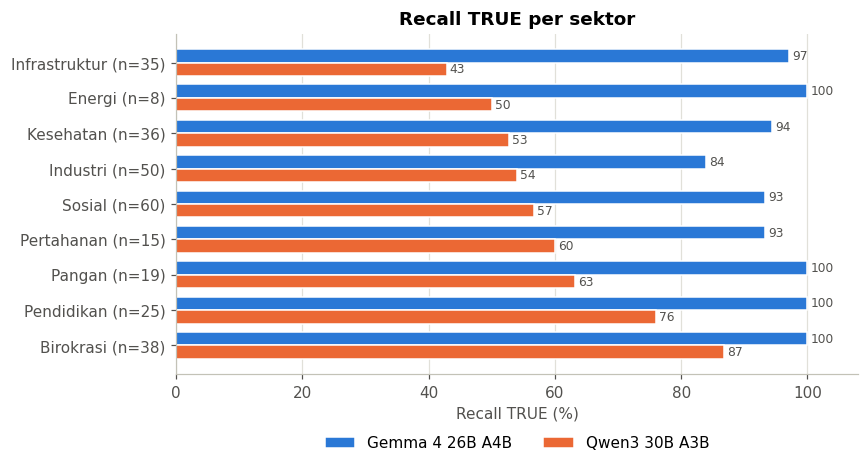

False negative Gemma 4 26B A4B di sektor Industri:
  no=20: KP 05.02.21 - Nilai investasi perusahaan industri dan perusahaan kawasan industri di KI Pulau Obi
  no=21: KP 05.02.23 - Nilai investasi perusahaan industri dan perusahaan kawasan industri di KI Buli
  no=86: PP 02.16 - Jumlah model pengelolaan sumber daya genetik termasuk digital sequence information pada sumber daya genetik
  no=124: KP 04.08.02 - Jumlah hub iptekin di K/L yang mengampu bidang prioritas yang dibentuk
  no=162: KP 04.08.02 - Jumlah hub tematik yang dikembangkan di BRIN
  no=197: KP 05.05.01 - Kontribusi perdagangan besar dan eceran terhadap PDRB di Pulau Kalimantan
  no=206: KP 02.12.07 - BUMD air minum berkinerja sehat
  no=256: KP 05.05.01 Jumlah usaha e-commerce di Pulau Kalimantan


In [46]:
# Hampir semua gold adalah TRUE, jadi yang dibandingkan per sektor adalah recall TRUE
t = df[df.gold]
sek = (t.groupby(["sektor", "model_nama"])["pred"].mean().unstack()[ORDER])
sek.insert(0, "n gold TRUE", t.drop_duplicates("row_no").groupby("sektor").size())
sek["selisih (G-Q)"] = sek[G] - sek[Q]
for nama in ORDER:
    sek[f"FN {nama}"] = t[t.model_nama == nama].groupby("sektor")["pred"].apply(lambda s: int((~s).sum()))
sek = sek.sort_values(Q)
display(sek.style.format({G: "{:.1%}", Q: "{:.1%}", "selisih (G-Q)": "{:+.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4.4))
y = np.arange(len(sek)); h = 0.38
for k, nama in enumerate(ORDER):
    b = ax.barh(y + (k - 0.5) * h, sek[nama] * 100, height=h, color=COLORS[nama],
                edgecolor="white", linewidth=1, label=nama)
    ax.bar_label(b, fmt="%.0f", padding=2, fontsize=8, color="#52514e")
ax.set_yticks(y, [f"{s} (n={n})" for s, n in zip(sek.index, sek["n gold TRUE"])]); ax.invert_yaxis()
ax.set_xlabel("Recall TRUE (%)"); ax.set_xlim(0, 108)
ax.set_title("Recall TRUE per sektor")
ax.grid(axis="y", visible=False)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.14))
plt.tight_layout(); plt.show()

terbanyak = sek[f"FN {G}"].idxmax()
print(f"False negative {G} di sektor {terbanyak}:")
for _, r in t[(t.model_nama == G) & (t.sektor == terbanyak) & ~t.pred].iterrows():
    print(f"  no={r['row_no']}: {str(r['sub_indikator'])[:120]}")

**Insight.**

- Kelemahan Qwen merata: recall TRUE di bawah 65% pada 7 dari 9 sektor, terendah Infrastruktur (42,9%, 20 FN dari 35). Masalahnya ada pada cara Qwen memutuskan, tidak pada topik indikatornya.
- Gemma hanya lemah di Industri (84,0%), yang menyumbang 8 dari 16 FN-nya. Empat dari delapan indikator itu terikat pada satu lokasi (KI Pulau Obi, KI Buli, Pulau Kalimantan).
- Energi (n=8) dibaca sebagai indikasi saja.

### 6.3 Di mana kedua model tidak sepakat, dan siapa yang benar saat itu?

In [47]:
bg, bq = wide[f"benar_{G}"].astype(bool), wide[f"benar_{Q}"].astype(bool)
pg, pq = wide[f"pred_{G}"].astype(bool), wide[f"pred_{Q}"].astype(bool)

pasangan = pd.DataFrame(
    [[int((bg & bq).sum()),  int((bg & ~bq).sum())],
     [int((~bg & bq).sum()), int((~bg & ~bq).sum())]],
    index=[f"{G} benar", f"{G} salah"], columns=[f"{Q} benar", f"{Q} salah"])
display(pasangan)

arah = pd.crosstab(pg.map({True: "TRUE", False: "FALSE"}).rename(f"pred {G}"),
                   pq.map({True: "TRUE", False: "FALSE"}).rename(f"pred {Q}")).reindex(
                   index=["TRUE", "FALSE"], columns=["TRUE", "FALSE"], fill_value=0)
display(arah)

sepakat = pg == pq
gold = wide["gold"].astype(bool)
print(f"Sepakat : {int(sepakat.sum())} baris, {int((pg[sepakat] == gold[sepakat]).sum())} di antaranya benar "
      f"({(pg[sepakat] == gold[sepakat]).mean():.1%})")
print(f"Berbeda : {int((~sepakat).sum())} baris, {G} benar {int(bg[~sepakat].sum())}, {Q} benar {int(bq[~sepakat].sum())}")
print(f"          gold pada baris berbeda: TRUE = {int(gold[~sepakat].sum())}, FALSE = {int((~gold[~sepakat]).sum())}")
sama_true = sepakat & pg
print(f"Keduanya menjawab TRUE : {int(sama_true.sum())} baris, {int(gold[sama_true].sum())} di antaranya gold TRUE")

,Qwen3 30B A3B benar,Qwen3 30B A3B salah
Gemma 4 26B A4B benar,168,103
Gemma 4 26B A4B salah,5,16


pred Qwen3 30B A3B,TRUE,FALSE
pred Gemma 4 26B A4B,,
TRUE,172,103
FALSE,5,12


Sepakat : 184 baris, 168 di antaranya benar (91.3%)
Berbeda : 108 baris, Gemma 4 26B A4B benar 103, Qwen3 30B A3B benar 5
          gold pada baris berbeda: TRUE = 108, FALSE = 0
Keduanya menjawab TRUE : 172 baris, 167 di antaranya gold TRUE


**Insight.**

- Ketidaksepakatan nyaris satu arah: dari 108 baris berbeda, 103 berbentuk Gemma TRUE dan Qwen FALSE, dan semuanya gold TRUE. Gemma unggul karena ambang Qwen jauh lebih ketat.
- Kesepakatan dua model tidak menangkap false positive: kelima FP ada di 172 baris yang dijawab TRUE oleh keduanya.
- Dua belas baris dijawab FALSE oleh keduanya: satu gold FALSE yang benar (no=44) dan 11 FN bersama, kandidat pertama untuk dicek ulang.

### 6.4 Mengapa 5 dari 6 indikator gold FALSE dijawab TRUE oleh kedua model?

In [48]:
gold_file = pd.read_csv(DATA_OUT.parent / "raw" / "gold_standard_sample.csv", encoding="utf-8-sig")
print("Tanggal gold dibuat :", sorted(gold_file["created_at"].astype(str).str[:10].unique()))
print("Tanggal run model   :", df.groupby("model_nama")["timestamp"].min().str[:10].to_dict())

no_false = wide.index[~wide["gold"]]
d = df[df.row_no.isin(no_false)].sort_values(["row_no", "model_nama"])

ringkas_fp = d.pivot(index="row_no", columns="model_nama", values=["pred", "source_type", "evidence_year", "domain"])
ringkas_fp = ringkas_fp.swaplevel(axis=1)[ORDER]
ringkas_fp.insert(0, "gold_suspect", d.drop_duplicates("row_no").set_index("row_no")["gold_suspect"])
display(ringkas_fp)

for no, grp in d.groupby("row_no"):
    r0 = grp.iloc[0]
    print("=" * 110)
    print(f"no={no} | {r0['sektor']} | {r0['kl']} | {str(r0['sub_indikator'])[:90]}")
    print(f"  Gold FALSE : {str(r0['summary_gold'])[:330]}")
    for _, r in grp.iterrows():
        print(f"  {r['model_nama']} | pred={r['pred']}")
        print(f"      Summary  : {str(r['summary_pred'])[:330]}")
        print(f"      URL      : {r['source_url_pred'] if pd.notna(r['source_url_pred']) else '(tidak ada)'}")
        print(f"      Cuplikan : {str(r['teks_sumber_dikutip'])[:260] or '(tidak ada)'}")

Tanggal gold dibuat : ['2025-12-10']
Tanggal run model   : {'Gemma 4 26B A4B': '2026-09-18', 'Qwen3 30B A3B': '2026-09-17'}


model_nama gold_suspect Gemma 4 26B A4B                                                           Qwen3 30B A3B                                                      
                                   pred  source_type evidence_year                         domain          pred  source_type evidence_year                     domain
row_no                                                                                                                                                               
11                 True            True          lkj          2025      ditjenbun.pertanian.go.id          True          lkj          2025  ditjenbun.pertanian.go.id
12                False            True          lkj          2025  ppvtpp.setjen.pertanian.go.id          True        media          2025        psp.pertanian.go.id
44                False           False        media          2025    www.bangda.kemendagri.go.id         False    tidak_ada     tidak_ada                        NaN
171               False            True          lkj          2025            www.kehutanan.go.id          True        media          2025      ksdae.kehutanan.go.id
173               False            True          lkj          2025          ksdae.kehutanan.go.id          True        media          2025          www.instagram.com
186               False            True  siaran_pers          2025                  kemenlh.go.id          True  siaran_pers          2025              kemenlh.go.id

no=11 | Pangan | KEMENTERIAN PERTANIAN | KP 02.10.17 - Produksi vanili
  Gold FALSE : Program belum berjalan, ditandai dengan tidak ditemukannya bukti publikasi resmi yang menunjukkan adanya program peningkatan produksi vanili berjalan pada Tahun 2025. Realisasi kegiatan pengembangan kawasan tanaman semusim dan rempah Direktorat Jenderal Perkebunan Tahun 2025 diarahkan ke pala, kakao, dan tebu, tanpa vanili. Kegi
  Gemma 4 26B A4B | pred=True
      Summary  : Program berjalan, ditandai dengan adanya Laporan Kinerja (LAKIN) Ditjen Perkebunan Tahun 2025 yang secara spesifik melaporkan capaian kinerja komoditas vanili dalam periode Renstra 2025-2029. Dokumen tersebut menunjukkan bahwa kegiatan teknis dan pengawalan produksi komoditas perkebunan, termasuk vanili, telah dilaksanakan pada 
      URL      : https://ditjenbun.pertanian.go.id/template/uploads/2026/03/LAKIN-DITJENBUN-2025.pdf
      Cuplikan : - Untitled - Ditjen Perkebunan: LAKIN Tahun 2025 merupakan laporan kinerja perdana pada

**Insight.** Kedua model salah pada 5 baris yang sama, tetapi penyebabnya berbeda:

- **Gold tertinggal (no=11, no=173).** Gold dibuat 10 Desember 2025, model dijalankan September 2026 dan menemukan LKj 2025 yang terbit setelahnya. Di dua baris ini kemungkinan besar model yang benar.
- **Kegiatan terkait dianggap bukti (no=12, no=186, dan Qwen pada no=171).** Contohnya Rakornas Kehati 2025 dipakai sebagai bukti fasilitasi unit pengelola taman kehati, padahal prompt menggolongkan rapat sebagai FALSE.
- **Dokumen dari tahun yang salah (Gemma pada no=171).** Laporan Kinerja Triwulan II TA 2026 dicatat sebagai bukti 2025.
- Satu-satunya baris yang dijawab benar (no=44) adalah baris yang punya bukti positif bahwa program masih tahap perencanaan. Model tidak bisa membuktikan ketiadaan lewat pencarian.

### 6.5 Mengapa Qwen punya 114 false negative, sedangkan Gemma hanya 16?

model_nama,Gemma 4 26B A4B,Qwen3 30B A3B
kategori,,
A. Tidak ada hasil pencarian sama sekali,1,0
"B. Ada pencarian kosong, bukti tidak ditemukan",4,30
"C. Hasil ada, tidak ada yang dianggap bukti",5,28
D. Bukti dianggap hanya perencanaan/target,6,38
"E. Bukti ditemukan, dinilai belum cukup",0,18


model_nama,Gemma 4 26B A4B,Qwen3 30B A3B
kelompok,,
Retrieval,5 (31%),30 (26%)
Relevansi,5 (31%),28 (25%)
Penalaran,6 (38%),56 (49%)


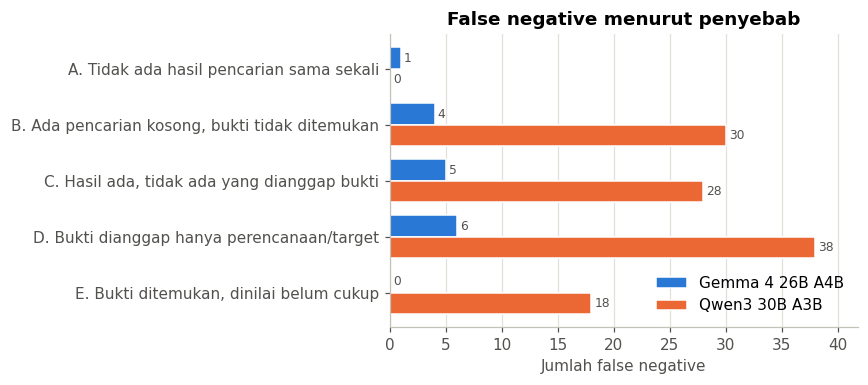

Gemma 4 26B A4B : pada 0 dari 5 FN yang bisa dibandingkan, URL bukti Qwen3 30B A3B muncul di hasil pencariannya sendiri
Qwen3 30B A3B   : pada 31 dari 100 FN yang bisa dibandingkan, URL bukti Gemma 4 26B A4B muncul di hasil pencariannya sendiri

FN bersama (kedua model menjawab FALSE pada gold TRUE): 11 indikator; hanya Gemma 4 26B A4B: 5; hanya Qwen3 30B A3B: 103
Kategori A | Gemma 4 26B A4B | no=157 | 0 pencarian | Program belum berjalan, ditandai dengan tidak ditemukannya bukti kegiatan konkret Kemenpora terkait indikator persentase penduduk berolahraga pada tahun 2025. Kata kunci pencarian yang diberikan (ekspor Sumatera) tidak relevan dengan indikator sosial/olahraga yang diminta.
--------------------------------------------------------------------------------------------------------------
no=7 | D. Bukti dianggap hanya perencanaan/target | PP 02.12 - Efisiensi pemanfaatan air irigasi
  Qwen3 30B A3B (FALSE): Program belum berjalan, ditandai dengan hanya terdapat target efisiensi 

In [49]:
# Tiap false negative (gold TRUE, pred FALSE) dipilah dengan aturan berurutan: aturan pertama yang cocok dipakai
POLA_RENCANA = r"renstra|perencanaan|rencana|target|\brkp\b|rpjmn|dokumen strategis"

def kategori_fn(r):
    if r["n_hasil"] == 0:
        return "A. Tidak ada hasil pencarian sama sekali"
    if r["source_type"] == "tidak_ada" and r["n_search_gagal"] > 0:
        return "B. Ada pencarian kosong, bukti tidak ditemukan"
    if r["source_type"] == "tidak_ada":
        return "C. Hasil ada, tidak ada yang dianggap bukti"
    if re.search(POLA_RENCANA, str(r["summary_pred"]).lower()):
        return "D. Bukti dianggap hanya perencanaan/target"
    return "E. Bukti ditemukan, dinilai belum cukup"

KELOMPOK = {"A": "Retrieval", "B": "Retrieval", "C": "Relevansi", "D": "Penalaran", "E": "Penalaran"}

fn = df[df.gold & ~df.pred].copy()
fn["kategori"] = fn.apply(kategori_fn, axis=1)
fn["kelompok"] = fn["kategori"].str[0].map(KELOMPOK)

tax = pd.crosstab(fn["kategori"], fn["model_nama"]).reindex(columns=ORDER, fill_value=0)
kel = pd.crosstab(fn["kelompok"], fn["model_nama"]).reindex(["Retrieval", "Relevansi", "Penalaran"]).reindex(
    columns=ORDER, fill_value=0)
display(tax)
display((kel.astype(str) + " (" + (kel / kel.sum()).map("{:.0%}".format) + ")"))

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(tax)); h = 0.38
for k, nama in enumerate(ORDER):
    b = ax.barh(y + (k - 0.5) * h, tax[nama], height=h, color=COLORS[nama],
                edgecolor="white", linewidth=1, label=nama)
    ax.bar_label(b, padding=2, fontsize=8, color="#52514e")
ax.set_yticks(y, tax.index); ax.invert_yaxis()
ax.set_xlabel("Jumlah false negative"); ax.set_title("False negative menurut penyebab")
ax.set_xlim(0, tax.to_numpy().max() * 1.1)
ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

# Cek silang: apakah URL bukti yang dipakai model lain (yang menjawab benar) sebenarnya ikut muncul
# di hasil pencarian model ini? Bila ya, model ini sudah melihat bukti yang sama tetapi menolaknya.
url_terlihat = {k: {h.get("url") for t in L for h in (t.get("hasil") or [])} for k, L in log_map.items()}
lain = df.set_index(["model_nama", "row_no"])
for nama in ORDER:
    m_lain = Q if nama == G else G
    terlihat = []
    for _, r in fn[fn.model_nama == nama].iterrows():
        o = lain.loc[(m_lain, r["row_no"])]
        if o["pred"] and o["benar"] and o["url_dari_search"]:
            terlihat.append(o["source_url_pred"] in url_terlihat[(nama, r["row_no"])])
    print(f"{nama:<16}: pada {sum(terlihat)} dari {len(terlihat)} FN yang bisa dibandingkan, URL bukti {m_lain} "
          f"muncul di hasil pencariannya sendiri")

fn_g, fn_q = set(fn.loc[fn.model_nama == G, "row_no"]), set(fn.loc[fn.model_nama == Q, "row_no"])
print(f"\nFN bersama (kedua model menjawab FALSE pada gold TRUE): {len(fn_g & fn_q)} indikator; "
      f"hanya {G}: {len(fn_g - fn_q)}; hanya {Q}: {len(fn_q - fn_g)}")

for _, r in fn[fn.kategori.str.startswith("A")].iterrows():
    print(f"Kategori A | {r['model_nama']} | no={r['row_no']} | {r['n_search']} pencarian | {str(r['summary_pred'])[:330]}")

# Dua contoh kelompok penalaran pada Qwen, berdampingan dengan jawaban Gemma untuk indikator yang sama
for no in [7, 93]:
    r = fn[(fn.model_nama == Q) & (fn.row_no == no)]
    if r.empty:
        continue
    r, o = r.iloc[0], lain.loc[(G, no)]
    print("-" * 110)
    print(f"no={no} | {r['kategori']} | {str(r['sub_indikator'])[:80]}")
    print(f"  {Q} (FALSE): {str(r['summary_pred'])[:300]}")
    print(f"  {G} ({str(o['pred']).upper()}): {str(o['summary_pred'])[:300]}")

**Insight.**

- Separuh FN Qwen (56 dari 114, 49%) adalah bukti yang sudah ditemukan lalu ditolak: dianggap sekadar perencanaan atau target (38) atau dinilai belum cukup (18). Pada 31 dari 100 FN yang bisa dibandingkan, URL bukti Gemma muncul di hasil pencarian Qwen sendiri.
- Seperempat (30) berakar pada pencarian yang kosong, dan seperempat lagi (28) punya hasil tetapi tidak ada yang dikenali sebagai bukti.
- Dari 16 FN Gemma, 11 juga FN pada Qwen. Kasus no=157 bukan kesalahan model: kolom `keywords` di data input berisi "ekspor Sumatera" untuk indikator olahraga.

### 6.6 Bagaimana model memakai pencarian, dan apakah pencarian kosong berkaitan dengan salah jawab?

In [50]:
# Pencarian "kosong" = tidak mengembalikan satu pun hasil.
# Pencarian "ber-site:" = dibatasi ke satu domain, lewat parameter `situs` atau operator site: di kueri.
calls = []
for (nama, row_no), L in log_map.items():
    for urutan, t in enumerate(L, 1):
        q = t.get("query") or ""
        calls.append({"model_nama": nama, "row_no": row_no, "urutan": urutan,
                      "situs": t.get("situs") or "".join(re.findall(r"site:(\S+)", q.lower())[:1]),
                      "pakai_site": bool(t.get("situs")) or ("site:" in q.lower()),
                      "n_hasil": len(t.get("hasil") or [])})
calls = pd.DataFrame(calls)
calls["kosong"] = calls["n_hasil"] == 0

cari = pd.DataFrame({
    nama: {
        "Total pencarian": len(c),
        "Rata-rata pencarian per indikator": f"{len(c) / 292:.2f}",
        "Indikator dengan 3 pencarian": int((c.groupby("row_no").size() == 3).sum()),
        "Pencarian ber-site:": f"{c['pakai_site'].sum()} ({c['pakai_site'].mean():.1%})",
        "  - pada pencarian pertama": f"{c.loc[c.urutan == 1, 'pakai_site'].sum()} dari {(c.urutan == 1).sum()}",
        "  - pada pencarian ke-2 dan seterusnya": f"{c.loc[c.urutan > 1, 'pakai_site'].sum()} dari {(c.urutan > 1).sum()}",
        "Pencarian kosong": f"{c['kosong'].sum()} ({c['kosong'].mean():.1%})",
        "Kosong saat ber-site:": f"{c.loc[c.pakai_site, 'kosong'].sum()} ({c.loc[c.pakai_site, 'kosong'].mean():.1%})",
        "Kosong saat tanpa site:": f"{c.loc[~c.pakai_site, 'kosong'].sum()} ({c.loc[~c.pakai_site, 'kosong'].mean():.1%})",
    } for nama, c in calls.groupby("model_nama")
})[ORDER]
display(cari)

# Hubungan dengan hasil akhir, hanya pada indikator gold TRUE
df["ada_gagal"] = df["n_search_gagal"] > 0
t = (df[df.gold].groupby(["model_nama", "ada_gagal"])["pred"].agg(["size", "sum", "mean"])
       .rename(columns={"size": "n gold TRUE", "sum": "dijawab TRUE", "mean": "recall TRUE"}))
t["recall TRUE"] = t["recall TRUE"].map("{:.1%}".format)
t.index = t.index.set_names(["Model", "Ada pencarian kosong?"])
display(t)

print("Domain `situs` yang paling sering mengembalikan 0 hasil:")
for nama in ORDER:
    top = calls[(calls.model_nama == nama) & calls.kosong & calls.situs.ne("")]["situs"].value_counts().head(6)
    print(f"  {nama:<16}: " + (", ".join(f"{k} ({v})" for k, v in top.items()) or "-"))

,Gemma 4 26B A4B,Qwen3 30B A3B
Total pencarian,604,876
Rata-rata pencarian per indikator,2.07,3.00
Indikator dengan 3 pencarian,79,292
Pencarian ber-site:,138 (22.8%),576 (65.8%)
- pada pencarian pertama,0 dari 291,0 dari 292
- pada pencarian ke-2 dan seterusnya,138 dari 313,576 dari 584
Pencarian kosong,21 (3.5%),90 (10.3%)
Kosong saat ber-site:,21 (15.2%),90 (15.6%)
Kosong saat tanpa site:,0 (0.0%),0 (0.0%)


n gold TRUE  dijawab TRUE recall TRUE
Model           Ada pencarian kosong?                                       
Gemma 4 26B A4B False                          265           255       96.2%
                True                            21            15       71.4%
Qwen3 30B A3B   False                          221           154       69.7%
                True                            65            18       27.7%

Domain `situs` yang paling sering mengembalikan 0 hasil:
  Gemma 4 26B A4B : kemenlh.go.id (4), brin.go.id (3), kemenpppa.go.id (2), esdm.go.id (1), dephub.go.id (1), komdigi.go.id (1)
  Qwen3 30B A3B   : kemenpppa.go.id (6), emonev.bappenas.go.id (6), kemenperin.go.id (5), kemenkes.go.id (4), kemenbud.go.id (4), kemenpu.go.id (4)


**Insight.**

- Qwen selalu memakai 3 pencarian. Gemma rata-rata 2,07 dan berhenti begitu bukti dirasa cukup.
- Qwen membatasi domain pada 576 dari 584 pencarian lanjutan, Gemma pada 138 dari 313.
- Semua pencarian kosong berasal dari `site:`, dengan tingkat kosong yang sama (sekitar 15%). Qwen hanya memakainya empat kali lebih sering: 90 pencarian kosong berbanding 21.
- Bila ada pencarian kosong, recall TRUE turun dari 96,2% ke 71,4% (Gemma) dan dari 69,7% ke 27,7% (Qwen).

### 6.7 Sumber apa yang dikutip model sebagai bukti?

,Gemma 4 26B A4B,Qwen3 30B A3B
Baris dengan URL bukti,291 dari 292,273 dari 292
URL tidak ada di hasil pencarian (karangan),9 (3.1%),39 (14.3%)
- saat pred TRUE,4,1
- saat pred FALSE,5,38
Domain .go.id (dari baris ber-URL),88.3%,86.1%
Bukti bertahun 2025,98.6%,78.4%
source_type = tidak_ada,10,59


jumlah baris                  dijawab TRUE                 dijawab FALSE              
model_nama  Gemma 4 26B A4B Qwen3 30B A3B Gemma 4 26B A4B Qwen3 30B A3B Gemma 4 26B A4B Qwen3 30B A3B
source_type                                                                                          
lkj                      78            84              78            62               0            22
siaran_pers             139            88             138            84               1             4
bappenas                 12            22              10            12               2            10
bps_setkab                9             6               9             1               0             5
renstra                   0             1               0             0               0             1
media                    44            32              40            18               4            14
tidak_ada                10            59               0             0              10            59

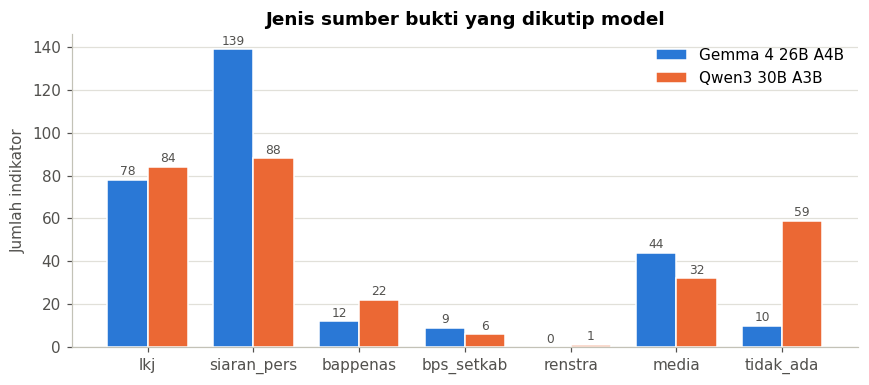

Lima domain yang paling sering dikutip:
  Gemma 4 26B A4B : satudata.kemenpora.go.id (13), kemkes.go.id (8), www.facebook.com (8), peraturan.bpk.go.id (7), api.kemenpar.go.id (7)
  Qwen3 30B A3B   : kemenlh.go.id (9), api.kemenpar.go.id (8), satudata.kemenpora.go.id (7), brin.go.id (6), pu.go.id (6)


In [51]:
df["url_ada"] = df["source_url_pred"].fillna("").astype(str).str.strip().ne("")

def ringkas_bukti(d):
    ada = d[d["url_ada"]]
    karang = ~ada["url_dari_search"]
    return {
        "Baris dengan URL bukti": f"{len(ada)} dari {len(d)}",
        "URL tidak ada di hasil pencarian (karangan)": f"{int(karang.sum())} ({karang.mean():.1%})",
        "  - saat pred TRUE": int((karang & ada.pred).sum()),
        "  - saat pred FALSE": int((karang & ~ada.pred).sum()),
        "Domain .go.id (dari baris ber-URL)": f"{ada['domain_goid'].mean():.1%}",
        "Bukti bertahun 2025": f"{d['evidence_year'].astype(str).str[:4].eq('2025').mean():.1%}",
        "source_type = tidak_ada": int(d["source_type"].eq("tidak_ada").sum()),
    }

display(pd.DataFrame({nama: ringkas_bukti(d) for nama, d in df.groupby("model_nama")})[ORDER])

st_order = ["lkj", "siaran_pers", "bappenas", "bps_setkab", "renstra", "media", "tidak_ada"]
st = pd.crosstab(df["source_type"], df["model_nama"]).reindex(st_order).fillna(0).astype(int)[ORDER]
true_st = (df[df.pred].groupby(["source_type", "model_nama"]).size().unstack()
             .reindex(index=st_order, columns=ORDER).fillna(0).astype(int))
display(pd.concat({"jumlah baris": st, "dijawab TRUE": true_st, "dijawab FALSE": st - true_st}, axis=1))

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(st)); w = 0.38
for k, nama in enumerate(ORDER):
    b = ax.bar(x + (k - 0.5) * w, st[nama], width=w, color=COLORS[nama],
               edgecolor="white", linewidth=1, label=nama)
    ax.bar_label(b, fontsize=8, padding=1, color="#52514e")
ax.set_xticks(x, st.index); ax.set_ylabel("Jumlah indikator")
ax.set_title("Jenis sumber bukti yang dikutip model")
ax.grid(axis="x", visible=False); ax.legend()
plt.tight_layout(); plt.show()

print("Lima domain yang paling sering dikutip:")
for nama in ORDER:
    top = df.loc[(df.model_nama == nama) & df.url_ada, "domain"].value_counts().head(5)
    print(f"  {nama:<16}: " + ", ".join(f"{k} ({v})" for k, v in top.items()))

**Insight.**

- Siaran pers dan LKj mencakup 74% bukti Gemma dan 59% bukti Qwen.
- Qwen menemukan dokumen resmi tetapi menolak isinya: 22 dari 84 baris ber-LKj tetap dijawab FALSE, sedangkan semua 78 baris ber-LKj Gemma dijawab TRUE.
- Qwen berakhir tanpa sumber pada 59 baris (Gemma 10), semuanya dijawab FALSE.
- Gemma lebih permisif: 40 dari 44 baris bersumber media dijawab TRUE, dan facebook.com serta instagram.com masuk lima domain teratasnya.
- URL karangan hampir hanya muncul pada jawaban FALSE: 38 dari 39 pada Qwen.

### 6.8 Apakah `confidence` yang dilaporkan model bisa dipakai memilah jawaban yang salah?

size  mean  median  min  max
Model           Benar?                              
Gemma 4 26B A4B False     21  86.9    90.0   75  100
                True     271  90.4    90.0   70  100
Qwen3 30B A3B   False    119  88.9    90.0   70   95
                True     173  89.9    90.0   85   95

Nilai confidence yang muncul:
  Gemma 4 26B A4B : 70->1, 75->1, 80->14, 85->28, 90->178, 95->68, 100->2
  Qwen3 30B A3B   : 70->4, 75->3, 80->2, 85->17, 90->251, 95->15

Bila baris dengan confidence < 90 dikirim ke peninjau:
  Gemma 4 26B A4B : 44 baris ditinjau, memuat 10 dari 21 kesalahan
  Qwen3 30B A3B   : 26 baris ditinjau, memuat 9 dari 119 kesalahan


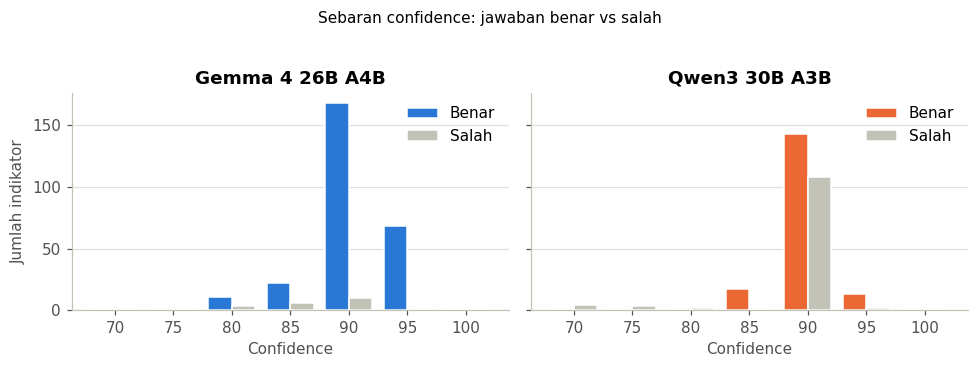

In [52]:
conf = (df.groupby(["model_nama", "benar"])["confidence"]
          .agg(["size", "mean", "median", "min", "max"]).round(1))
conf.index = conf.index.set_names(["Model", "Benar?"])
display(conf)

print("Nilai confidence yang muncul:")
for nama in ORDER:
    vc = df.loc[df.model_nama == nama, "confidence"].value_counts().sort_index()
    print(f"  {nama:<16}: " + ", ".join(f"{k}->{v}" for k, v in vc.items()))

# Kalau ambang confidence dipakai sebagai saringan: berapa kesalahan yang tertangkap?
print("\nBila baris dengan confidence < 90 dikirim ke peninjau:")
for nama in ORDER:
    d = df[df.model_nama == nama]
    rendah = d["confidence"] < 90
    print(f"  {nama:<16}: {int(rendah.sum())} baris ditinjau, memuat {int((rendah & ~d.benar).sum())} "
          f"dari {int((~d.benar).sum())} kesalahan")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
nilai = sorted(df["confidence"].unique())
x = np.arange(len(nilai)); w = 0.4
for ax, nama in zip(axes, ORDER):
    d = df[df.model_nama == nama]
    n_benar = d[d.benar]["confidence"].value_counts().reindex(nilai, fill_value=0)
    n_salah = d[~d.benar]["confidence"].value_counts().reindex(nilai, fill_value=0)
    ax.bar(x - w / 2, n_benar, width=w, color=COLORS[nama], edgecolor="white", linewidth=1, label="Benar")
    ax.bar(x + w / 2, n_salah, width=w, color=ABU, edgecolor="white", linewidth=1, label="Salah")
    ax.set_xticks(x, nilai); ax.set_xlabel("Confidence"); ax.set_title(nama)
    ax.grid(axis="x", visible=False); ax.legend()
axes[0].set_ylabel("Jumlah indikator")
fig.suptitle("Sebaran confidence: jawaban benar vs salah", y=1.03, fontsize=10)
plt.tight_layout(); plt.show()

**Insight.** `confidence` tidak bisa dipakai memilah jawaban yang salah.

- Nilainya menumpuk di 90 (178 dari 292 pada Gemma, 251 dari 292 pada Qwen), dan median untuk jawaban benar maupun salah sama-sama 90.
- Meninjau semua baris dengan confidence di bawah 90 hanya menemukan 10 dari 21 kesalahan Gemma dan 9 dari 119 kesalahan Qwen.

### 6.9 Berapa biaya token dan waktu tiap model?

In [53]:
def ringkas_biaya(d):
    tok = d["in_tok"] + d["out_tok"]
    return {
        "Token input rata-rata": f"{d['in_tok'].mean():,.0f}",
        "Token output rata-rata": f"{d['out_tok'].mean():,.0f}",
        "Token total rata-rata per indikator": f"{tok.mean():,.0f}",
        "Token total seluruh run": f"{tok.sum():,.0f}",
        "Pencarian rata-rata per indikator": f"{d['n_search'].mean():.2f}",
        "Latensi rata-rata (dtk)": f"{d['latency_s'].mean():.1f}",
        "Latensi median (dtk)": f"{d['latency_s'].median():.1f}",
        "Latensi total (menit)": f"{d['latency_s'].sum() / 60:.1f}",
        "Jawaban benar": int(d["benar"].sum()),
        "Token per jawaban benar": f"{tok.sum() / d['benar'].sum():,.0f}",
    }

biaya = pd.DataFrame({nama: ringkas_biaya(d) for nama, d in df.groupby("model_nama")})[ORDER]
display(biaya)

tok = (df["in_tok"] + df["out_tok"]).groupby(df["model_nama"]).sum()
print(f"Token total {G} = {tok[G] / tok[Q]:.0%} dari {Q}")
print("Token input rata-rata menurut jumlah pencarian:")
per_cari = df.groupby(["n_search", "model_nama"])["in_tok"].agg(["size", "mean"]).unstack()
per_cari = per_cari.swaplevel(axis=1)[ORDER].rename(columns={"size": "n", "mean": "token input"})
display(per_cari.map(lambda v: "-" if pd.isna(v) else f"{v:,.0f}"))

,Gemma 4 26B A4B,Qwen3 30B A3B
Token input rata-rata,"4,275","7,449"
Token output rata-rata,256,345
Token total rata-rata per indikator,"4,531","7,794"
Token total seluruh run,"1,323,086","2,275,867"
Pencarian rata-rata per indikator,2.07,3.00
Latensi rata-rata (dtk),6.8,10.3
Latensi median (dtk),6.3,9.7
Latensi total (menit),33.3,50.1
Jawaban benar,271,173
Token per jawaban benar,"4,882","13,155"


Token total Gemma 4 26B A4B = 58% dari Qwen3 30B A3B
Token input rata-rata menurut jumlah pencarian:


model_nama Gemma 4 26B A4B             Qwen3 30B A3B            
                         n token input             n token input
n_search                                                        
0                        1         871             -           -
1                       59       2,256             -           -
2                      152       4,099             -           -
3                       79       6,115           292       7,449
4                        1       8,305             -           -

**Insight.**

- Gemma memakai 58% token Qwen (4.531 berbanding 7.794 per indikator) dan lebih cepat (median 6,3 berbanding 9,7 detik).
- Pendorong utamanya jumlah pencarian: token input Gemma naik sekitar 2.000 per pencarian tambahan, dan Qwen selalu mencari 3 kali.
- Per jawaban benar, Qwen menghabiskan sekitar 2,7 kali token Gemma (13.155 berbanding 4.882).

### 6.10 Bagaimana sebaran skor groundedness tiap model?

Skor groundedness,0,1,2
model_nama,,,
Gemma 4 26B A4B,82 (29.0%),11 (3.9%),190 (67.1%)
Qwen3 30B A3B,150 (51.9%),10 (3.5%),129 (44.6%)


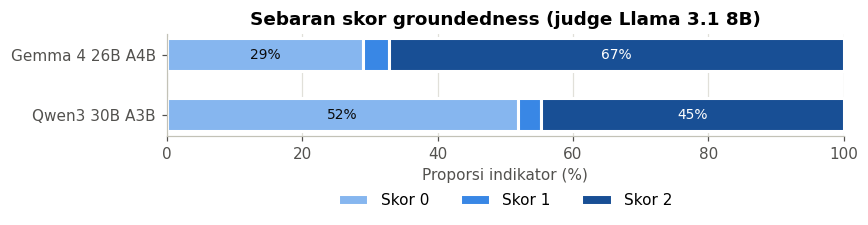

In [54]:
if ADA_JUDGE:
    hitung = (hj.groupby("model_nama")["judge_groundedness"].value_counts()
                .unstack().reindex(index=ORDER, columns=[0, 1, 2]).fillna(0).astype(int))
    dist = hitung.div(hitung.sum(axis=1), axis=0)
    display((hitung.astype(str) + " (" + dist.map("{:.1%}".format) + ")").rename_axis(columns="Skor groundedness"))

    fig, ax = plt.subplots(figsize=(8, 2.6))
    kiri = np.zeros(len(ORDER))
    for s in [0, 1, 2]:
        b = ax.barh(ORDER, dist[s] * 100, left=kiri, color=WARNA_SKOR[s], edgecolor="white", linewidth=2,
                    height=0.55, label=f"Skor {s}")
        ax.bar_label(b, labels=[f"{v:.0f}%" if v >= 6 else "" for v in dist[s] * 100], label_type="center",
                     color="#0b0b0b" if s == 0 else "white", fontsize=9)
        kiri += dist[s].values * 100
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("Proporsi indikator (%)")
    ax.set_title("Sebaran skor groundedness (judge Llama 3.1 8B)")
    ax.grid(axis="y", visible=False)
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.42))
    plt.tight_layout(); plt.show()
else:
    print("Belum ada hasil judge. Jalankan bagian 4.2 lebih dulu.")

**Insight.**

- Skor 0 jauh lebih banyak pada Qwen: 51,9% (150 dari 289) berbanding 29,0% pada Gemma (82 dari 283). Skor 1 hampir tidak dipakai (3,5% dan 3,9%), jadi judge praktis hanya memberi 0 atau 2.
- Selisih itu terutama berasal dari jawaban FALSE. Rata-rata groundedness jawaban FALSE yang salah hanya 0,40 (Qwen) dan 0,69 (Gemma), dan Qwen punya 115 jawaban FALSE sedangkan Gemma 17. Pada jawaban TRUE yang benar keduanya berdekatan: 1,42 (Gemma) dan 1,28 (Qwen).
- **Angka skor 0 kemungkinan terlalu tinggi.** Di contoh 4.4, dua dari lima alasan groundedness = 0 berbunyi "maks 1 kalimat", yaitu teks contoh di prompt yang disalin mentah oleh judge, dan contoh itu memuat skor 0. Pada no=53 judge menulis tahun 2025 tidak disebut, padahal cuplikannya memuat "Tahun 2025 dengan realisasi 3,78". Karena itu proporsi skor 0 tidak bisa dibaca sebagai "sekian persen summary dikarang".

### 6.11 Apakah jawaban yang benar punya summary yang lebih berdasar dan lebih relevan?

In [55]:
if ADA_JUDGE:
    KOL = ["judge_groundedness", "judge_rel_ringkasan", "judge_rel_sumber"]
    t = hj.groupby(["model_nama", "benar"])[KOL].mean().round(2)
    t.insert(0, "n", hj.groupby(["model_nama", "benar"]).size())
    t.index = t.index.set_names(["Model", "Benar?"])
    display(t)

    # Dipecah menurut label prediksi: summary jawaban FALSE biasanya berbunyi "bukti tidak ditemukan"
    p = hj.groupby(["model_nama", "pred", "benar"])[KOL].mean().round(2)
    p.insert(0, "n", hj.groupby(["model_nama", "pred", "benar"]).size())
    p.index = p.index.set_names(["Model", "Pred", "Benar?"])
    display(p)
else:
    print("Belum ada hasil judge. Jalankan bagian 4.2 lebih dulu.")

n  judge_groundedness  judge_rel_ringkasan  judge_rel_sumber
Model           Benar?                                                                
Gemma 4 26B A4B False    21                0.85                 0.19              0.67
                True    271                1.42                 1.55              1.60
Qwen3 30B A3B   False   119                0.44                 0.05              0.67
                True    173                1.27                 1.70              1.65

n  judge_groundedness  judge_rel_ringkasan  judge_rel_sumber
Model           Pred  Benar?                                                                
Gemma 4 26B A4B False False    16                0.69                 0.00              0.60
                      True      1                2.00                 0.00              0.00
                True  False     5                1.50                 0.80              0.80
                      True    270                1.42                 1.56              1.61
Qwen3 30B A3B   False False   114                0.40                 0.00              0.64
                      True      1                0.00                 0.00               NaN
                True  False     5                1.20                 1.20              1.00
                      True    172                1.28                 1.71              1.65

**Insight.**

- Jawaban benar mendapat skor lebih tinggi di semua dimensi, tetapi sebagian besar selisihnya adalah artefak judge: **semua jawaban FALSE mendapat relevansi ringkasan 0,00**, termasuk yang benar (no=44). Summary berbunyi "bukti tidak ditemukan" dinilai tidak relevan, padahal tetap membahas indikator yang ditanyakan. Jadi skor ini memisahkan jawaban TRUE dari FALSE, belum tentu benar dari salah.
- Perbandingan yang wajar adalah di antara jawaban TRUE. Di sana lima false positive punya relevansi lebih rendah daripada jawaban TRUE yang benar: relevansi sumber 0,80 berbanding 1,61 (Gemma) dan 1,00 berbanding 1,65 (Qwen). Groundedness tidak membedakan keduanya (1,50 berbanding 1,42, dan 1,20 berbanding 1,28).
- Ini sejalan dengan 5.1: aturan judge menangkap 3 dari 5 false positive pada tiap model, dari sebelumnya 0 dan 1. Harganya, baris yang perlu ditinjau naik dari 36 menjadi 126 (Gemma) dan dari 135 menjadi 197 (Qwen).

### 6.12 Sektor mana yang summary-nya paling kurang berdasar?

In [56]:
if ADA_JUDGE:
    per_sektor = hj.pivot_table(index="sektor", columns="model_nama",
                                values="judge_groundedness", aggfunc="mean")[ORDER]
    nol = (hj.assign(nol=hj["judge_groundedness"].eq(0))
             .pivot_table(index="sektor", columns="model_nama", values="nol", aggfunc="sum")[ORDER].astype(int))
    out = pd.concat({"rata-rata groundedness": per_sektor.round(2), "jumlah skor 0": nol}, axis=1)
    out.insert(0, "n", hj.drop_duplicates("row_no").groupby("sektor").size())
    display(out.sort_values(("rata-rata groundedness", Q)))
else:
    print("Belum ada hasil judge. Jalankan bagian 4.2 lebih dulu.")

n rata-rata groundedness                 jumlah skor 0              
model_nama               Gemma 4 26B A4B Qwen3 30B A3B Gemma 4 26B A4B Qwen3 30B A3B
sektor                                                                              
Infrastruktur  38                   1.29          0.74              12            24
Energi          8                   1.33          0.75               2             5
Sosial         61                   1.30          0.75              20            36
Industri       50                   1.45          0.92              13            27
Pertahanan     15                   1.71          0.93               2             8
Birokrasi      38                   1.42          0.94               9            17
Pendidikan     25                   1.64          1.00               4            12
Kesehatan      36                   1.19          1.06              14            16
Pangan         21                   1.35          1.52               6             5

**Insight.**

- Pada Qwen, sektor dengan groundedness terendah adalah Infrastruktur (0,74), Energi (0,75), dan Sosial (0,75). Ini hampir sama dengan urutan recall TRUE di 6.2, karena jawaban FALSE mendapat skor rendah dari judge. Untuk Qwen tabel ini tidak menambah informasi baru.
- Pada Gemma, yang terendah adalah Kesehatan (1,19, 14 skor 0 dari 36), padahal recall TRUE-nya di sektor itu 94,4%. Jadi di Kesehatan Gemma sering menjawab TRUE dengan summary yang menurut judge tidak didukung cuplikannya. Sektor ini layak dicek manual lebih dulu.
- Pangan adalah satu-satunya sektor tempat Qwen (1,52) di atas Gemma (1,35).
- Energi (n=8) dan Pertahanan (n=15) dibaca sebagai indikasi saja.